# 02 - Hilbert transform vs EMD / Hilbert-Huang transform (single detector)

The whitened data are non-stationary and contain several frequency components (noise + chirp).
A plain Hilbert transform assumes a single-component (mono-component) signal, so we first decompose the
data with **empirical mode decomposition (EMD)** into intrinsic mode functions (IMFs) and then apply the Hilbert
transform to each IMF (the **Hilbert-Huang transform**).

$$x(t)=\sum_{i=1}^{n}\mathrm{IMF}_i(t)+r(t),\qquad z_i(t)=\mathrm{IMF}_i+j\,H[\mathrm{IMF}_i]=A_i(t)e^{j\theta_i(t)},\qquad f_i(t)=\frac{1}{2\pi}\frac{d\theta_i}{dt}$$

$$HHS(t,f)=\sum_i A_i(t)\,\delta\big(f-f_i(t)\big)$$

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import numpy as np
import matplotlib.pyplot as plt
from gwhht.config import load_config
from gwhht.simulate import simulate_network
from gwhht.preprocess import preprocess_network
%matplotlib inline
from gwhht import plotting as P
from gwhht.hht import (analytic_signal, sift, hht_spectrum, frequency_transform,
                       reconstruction_error, peak_time)

In [2]:
cfg = load_config("../configs/default.yaml")
sim = simulate_network(cfg)
signal_wbp, data_wbp = preprocess_network(sim)

ifo, tt = "L1", sim.t_trigger
W = data_wbp[ifo].time_slice(tt + cfg.window[0], tt + cfg.window[1])      # whitened data segment
S = signal_wbp[ifo].time_slice(tt + cfg.window[0], tt + cfg.window[1])    # noise-free reference
t = np.asarray(W.sample_times) - tt
fs = cfg.fsamp

## 1. Plain Hilbert transform (baseline)

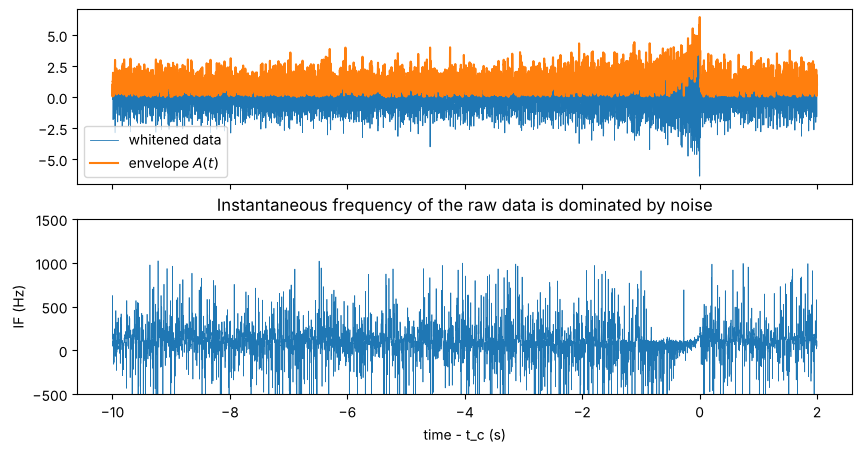

In [3]:
amp, phase, freq = analytic_signal(W, fs)
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
ax[0].plot(t, W, lw=0.6, label="whitened data"); ax[0].plot(t, amp, label="envelope $A(t)$"); ax[0].legend()
ax[1].plot(t[1:], freq, lw=0.5); ax[1].set(ylabel="IF (Hz)", xlabel="time - t_c (s)", ylim=(-500, 1500))
ax[1].set_title("Instantaneous frequency of the raw data is dominated by noise")
plt.show()

## 2. EMD

number of IMFs (incl. residual): 6


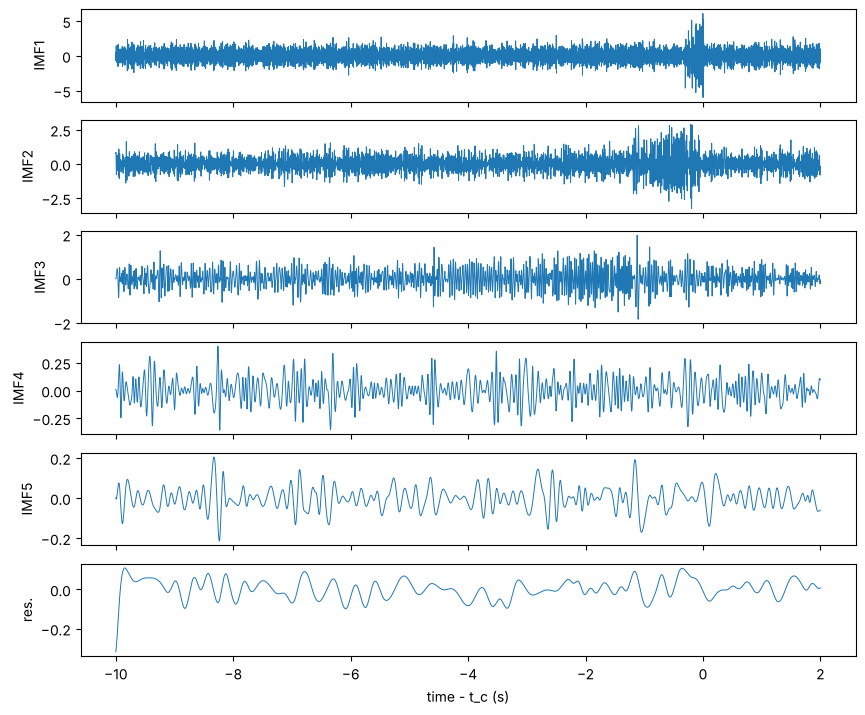

In [4]:
imfs = sift(W)
print("number of IMFs (incl. residual):", imfs.shape[1])
P.plot_imfs(imfs, t); plt.show()

## 3. Hilbert-Huang spectrum

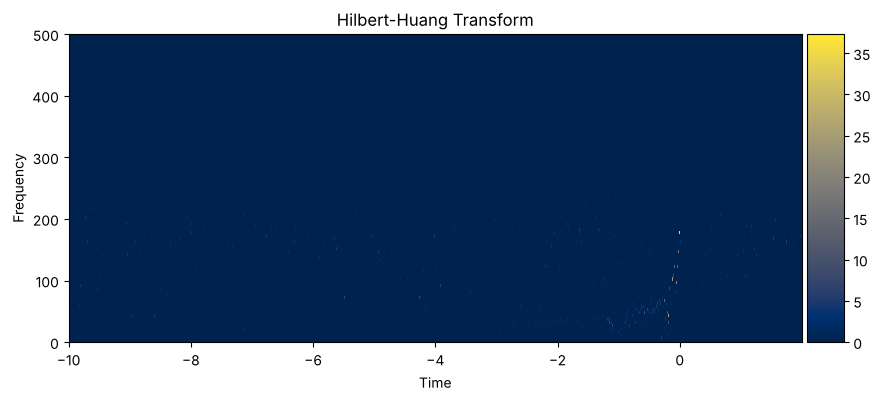

In [5]:
IP, IF, IA, f, hht = hht_spectrum(imfs, fs, freq_range=(0, 500, 100), method="nht")
P.plot_hht(hht, t, f, freq_lims=(0, 500)); plt.show()

## 4. Instantaneous amplitude and frequency of each IMF

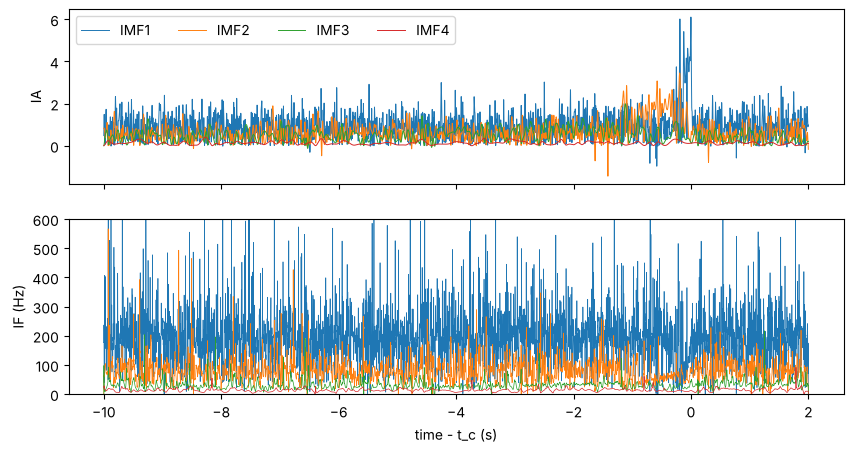

In [6]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
for k in range(min(4, imfs.shape[1] - 1)):
    ax[0].plot(t, IA[:, k], lw=0.7, label=f"IMF{k+1}")
    ax[1].plot(t, IF[:, k], lw=0.5)
ax[0].set_ylabel("IA"); ax[1].set(ylabel="IF (Hz)", xlabel="time - t_c (s)", ylim=(0, 600)); ax[0].legend(ncol=4)
plt.show()

## 5. Reconstruction error vs number of IMFs
EMD is complete: summing all IMFs (including the residual) reproduces the data exactly.

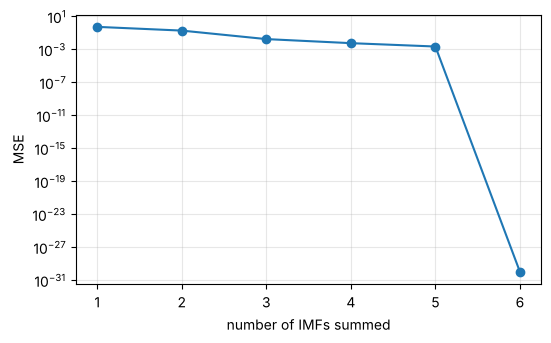

MSE with all IMFs: 6.67e-37


In [7]:
n = np.arange(1, imfs.shape[1] + 1)
err = [reconstruction_error(W, imfs, k) for k in n]
plt.figure(figsize=(6, 3.5)); plt.semilogy(n, np.maximum(err, 1e-30), "o-")
plt.xlabel("number of IMFs summed"); plt.ylabel("MSE"); plt.grid(alpha=0.3); plt.show()
print(f"MSE with all IMFs: {err[-1]:.2e}")

## 6. Merger-time estimate
Two crude estimators of the coalescence time: the highest peak of the whitened data, and the highest peak of IMF1.
Both are compared with the injected `t_c`.

In [8]:
lo, hi = tt + cfg.merger_search[0], tt + cfg.merger_search[1]
tabs = np.asarray(W.sample_times)
t_peak = peak_time(tabs, W, lo, hi)
t_imf1 = peak_time(tabs, imfs[:, 0], lo, hi)
t_sig = peak_time(tabs, S, lo, hi)
print(f"|t_peak(data) - t_c|     = {abs(t_peak - tt)*1e3:.2f} ms")
print(f"|t_peak(IMF1) - t_c|     = {abs(t_imf1 - tt)*1e3:.2f} ms")
print(f"|t_peak(noise-free) - t_c| = {abs(t_sig - tt)*1e3:.2f} ms   (floor set by the whitening/band-pass)")

|t_peak(data) - t_c|     = 1.70 ms
|t_peak(IMF1) - t_c|     = 1.70 ms
|t_peak(noise-free) - t_c| = 1.21 ms   (floor set by the whitening/band-pass)
